# I-JEPA: predict masked image regions in feature space

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/vision/ijepa.ipynb)

[I-JEPA](https://arxiv.org/abs/2301.08243) ([code](https://github.com/facebookresearch/ijepa)) encodes one visible context block and predicts the features of several target blocks. The targets come from an EMA copy of the encoder, so the model never reconstructs pixels.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [1]:
import torch

from torch_world import metrics, plots
from torch_world.envs import PointMass
from torch_world.masks import MultiBlockMask
from torch_world.models import IJEPA
from torch_world.nn import MaskedPredictor, VisionTransformer
from torch_world.utils import linear_schedule

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Multi-block masks
Four target blocks, plus one context block that avoids them.

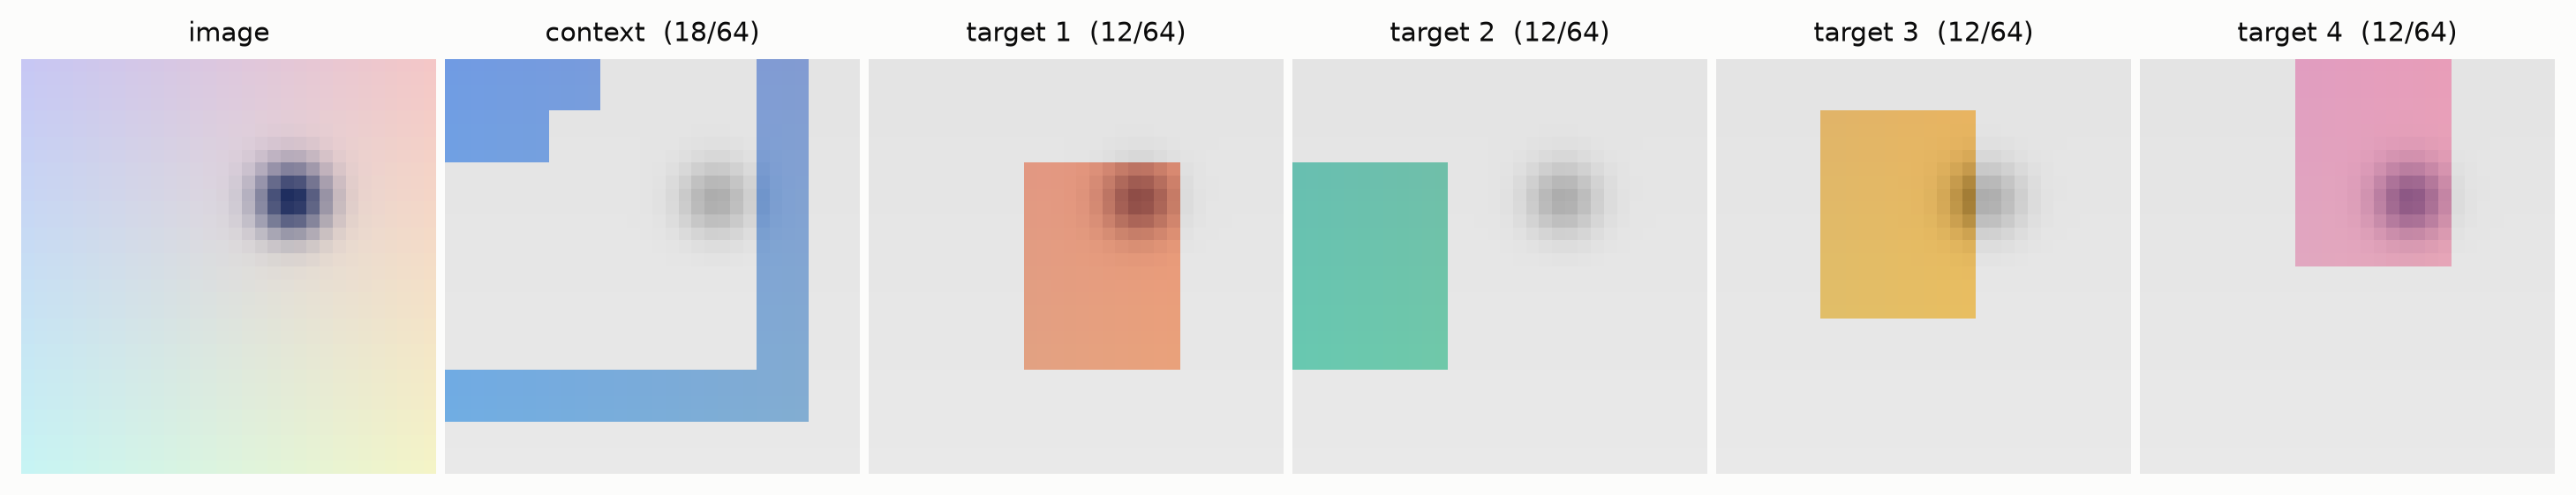

In [2]:
env = PointMass(batch_size=128, size=32, device=device)
encoder = VisionTransformer(img_size=32, patch_size=4, embed_dim=192, depth=6, num_heads=6)
masker = MultiBlockMask(encoder.grid, min_keep=4)

masks_enc, masks_pred = masker(1)
layers = {"context": masks_enc[0][0], **{f"target {i + 1}": m[0] for i, m in enumerate(masks_pred)}}
plots.masks(env.reset()[0], encoder.grid, layers)

## Train

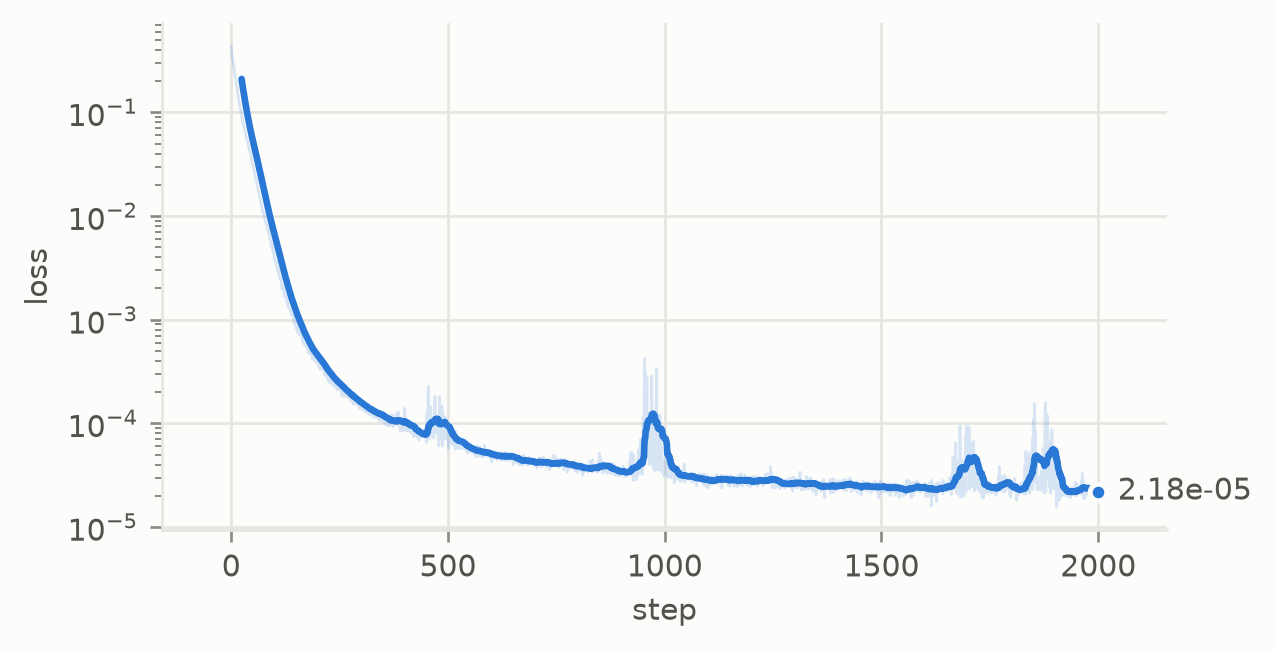

In [3]:
model = IJEPA(encoder, MaskedPredictor(encoder.grid, 192, predictor_dim=96, depth=4, num_heads=6)).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.04)

steps, log = 2000, {"smooth L1": []}
for step in range(steps):
    masks_enc, masks_pred = masker(128)
    loss = model(env.reset(), [m.to(device) for m in masks_enc], [m.to(device) for m in masks_pred])["loss"]
    opt.zero_grad()
    loss.backward()
    opt.step()
    model.update_target(linear_schedule(0.996, 1.0, step, steps))
    log["smooth L1"].append(loss.item())

plots.curves(log)

## What the features see
The top three principal components of the frozen patch features, after removing each patch position's average over images, shown as RGB. What remains is what changes from image to image: the point.

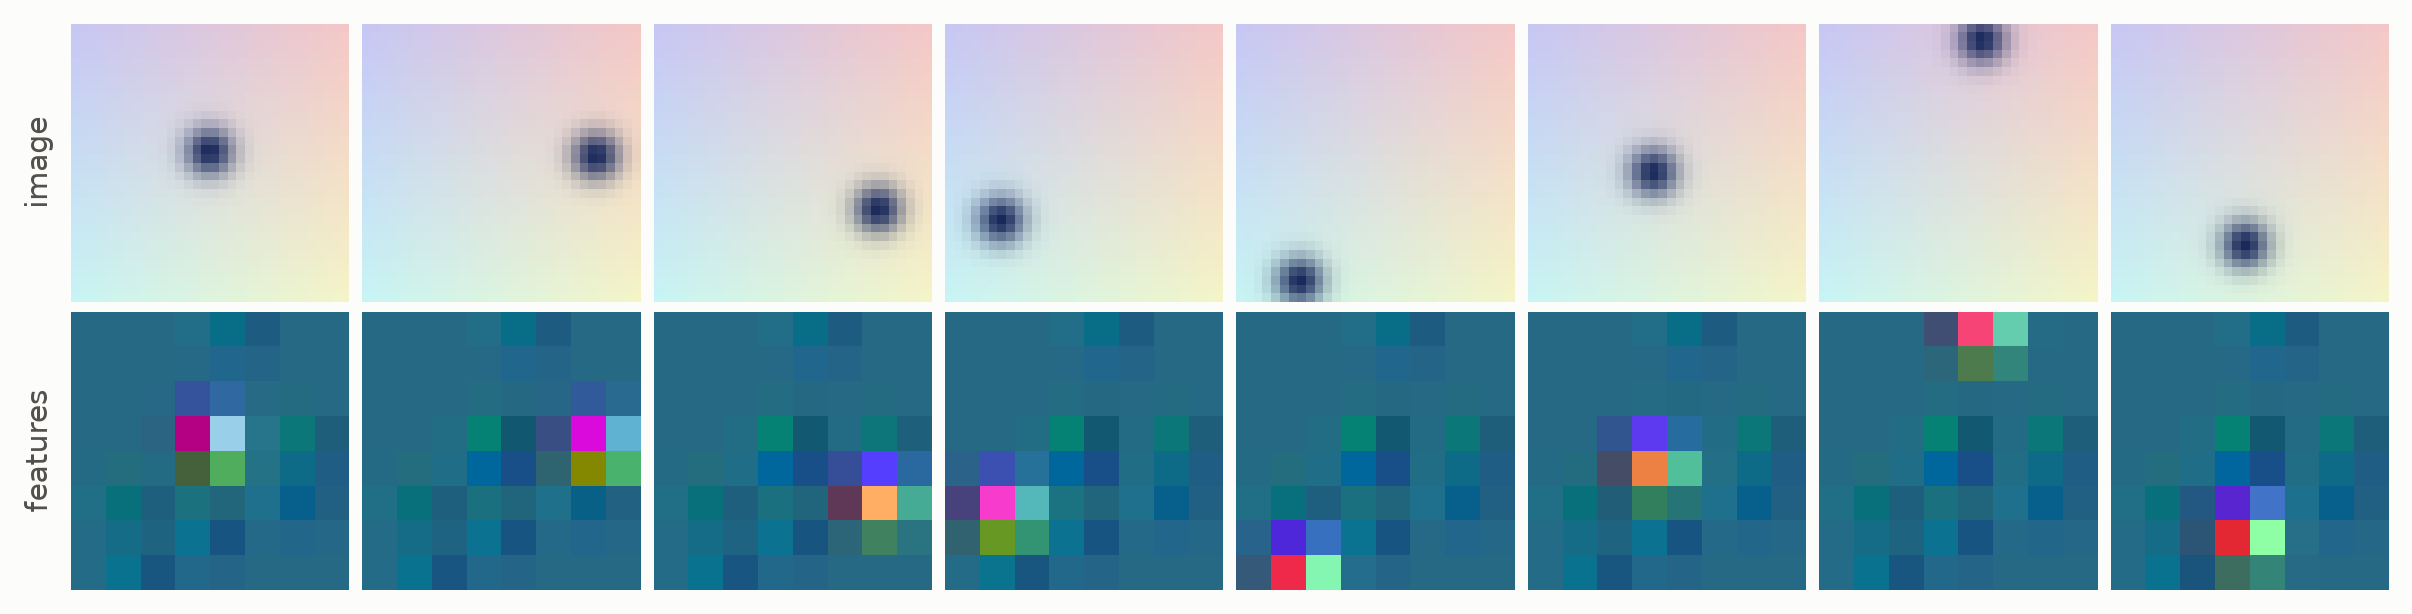

In [4]:
images = PointMass(batch_size=8, size=32, device=device).reset()
with torch.no_grad():
    h = model.target_encoder(images)
flat = (h - h.mean(0)).flatten(0, 1)
pcs = (flat - flat.mean(0)) @ torch.pca_lowrank(flat, q=3)[2]
pcs = (pcs - pcs.min(0).values) / (pcs.max(0).values - pcs.min(0).values)
features = pcs.view(8, *encoder.grid, 3).permute(0, 3, 1, 2)
features = torch.nn.functional.interpolate(features, size=32, mode="nearest")
plots.images(torch.cat([images, features]), rows=["image", "features"])

## How good are the features?
I-JEPA is evaluated on frozen features. Three metrics on 4096 fresh images (3584 to fit, 512 to test), against the same encoder at random initialization:
- **linear probe**: regresses the position of the point from average-pooled features, scored by R²;
- **k-NN**: classifies which cell of a 3×3 grid holds the point, by a vote of the 20 nearest training features, with no training at all (chance is 11%);
- **RankMe**: the effective rank of the pooled features, out of 192 dimensions; a collapsed encoder scores near 1.

The images are mostly empty background, so the pooled features share one large component that would dominate cosine similarity and the singular values; k-NN and RankMe therefore use centered features (`center=True`).

In [5]:
env = PointMass(batch_size=4096, size=32, device=device)
images = env.reset(generator=torch.Generator().manual_seed(7))
position = env.state
cell = ((position - env.low) / (env.high - env.low) * 3).long().clamp(0, 2)
cell = cell[:, 0] * 3 + cell[:, 1]

baseline = VisionTransformer(img_size=32, patch_size=4, embed_dim=192, depth=6, num_heads=6).to(device)
print(f"{'':12s}{'linear probe R²':>17s}{'k-NN':>8s}{'RankMe':>9s}")
for name, net in {"random init": baseline, "I-JEPA": model.target_encoder}.items():
    with torch.no_grad():
        z = torch.cat([net(x).mean(1) for x in images.split(1024)])
    linear = metrics.linear_probe(z[:3584], position[:3584], z[3584:], position[3584:])
    knn = metrics.knn_accuracy(z[:3584], cell[:3584], z[3584:], cell[3584:], center=True)
    print(f"{name:12s}{linear.score:17.3f}{knn.score:8.1%}{metrics.rankme(z, center=True):9.1f}")

              linear probe R²    k-NN   RankMe


random init             0.995   97.1%     13.8


I-JEPA                  0.995   95.3%     10.1
